<a href="https://colab.research.google.com/github/logilogilogi3/dcgan-cifar10-airplane/blob/main/dcgan%EA%B5%AC%ED%98%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Random Seed: 18


100%|██████████| 170M/170M [23:27<00:00, 121kB/s]


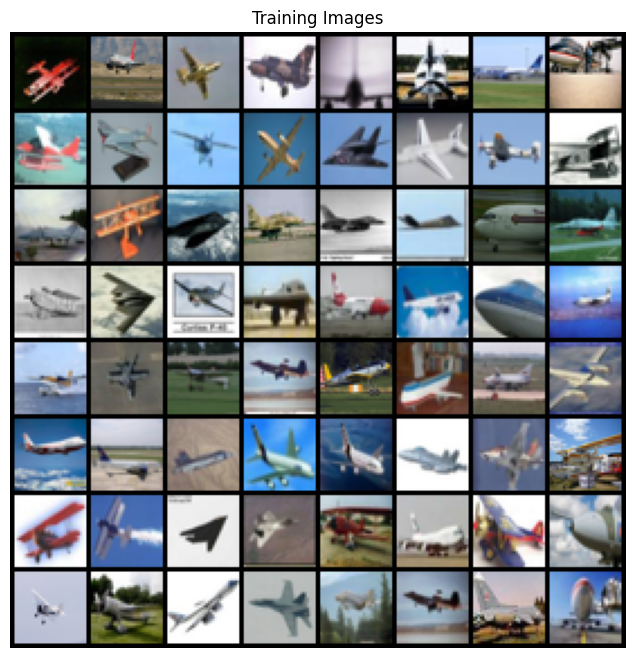

start training!...
[0/30][0/79]	Loss_D: 2.0037	Loss_G: 1.6043	D(x): 0.2262	D(G(z)): 0.2423 / 0.2243
[0/30][50/79]	Loss_D: 0.1647	Loss_G: 5.9051	D(x): 0.9435	D(G(z)): 0.0958 / 0.0034
[1/30][0/79]	Loss_D: 0.0356	Loss_G: 5.4891	D(x): 0.9756	D(G(z)): 0.0103 / 0.0051
[1/30][50/79]	Loss_D: 0.5085	Loss_G: 4.2612	D(x): 0.8230	D(G(z)): 0.2002 / 0.0282
[2/30][0/79]	Loss_D: 0.3050	Loss_G: 4.4497	D(x): 0.8601	D(G(z)): 0.1082 / 0.0149
[2/30][50/79]	Loss_D: 0.2344	Loss_G: 5.2192	D(x): 0.8468	D(G(z)): 0.0418 / 0.0074
[3/30][0/79]	Loss_D: 1.6994	Loss_G: 9.0547	D(x): 0.9397	D(G(z)): 0.6857 / 0.0021
[3/30][50/79]	Loss_D: 0.4680	Loss_G: 3.9213	D(x): 0.8450	D(G(z)): 0.2111 / 0.0303
[4/30][0/79]	Loss_D: 0.3430	Loss_G: 5.3080	D(x): 0.8906	D(G(z)): 0.1775 / 0.0088
[4/30][50/79]	Loss_D: 0.2716	Loss_G: 4.1870	D(x): 0.8539	D(G(z)): 0.0768 / 0.0210
[5/30][0/79]	Loss_D: 0.1758	Loss_G: 4.1118	D(x): 0.9318	D(G(z)): 0.0872 / 0.0239
[5/30][50/79]	Loss_D: 0.4971	Loss_G: 6.7366	D(x): 0.8559	D(G(z)): 0.2576 / 0.0017
[6/

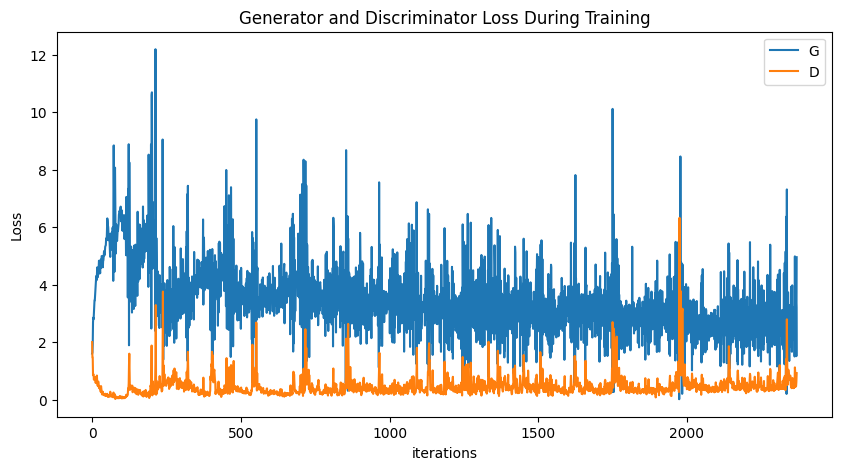

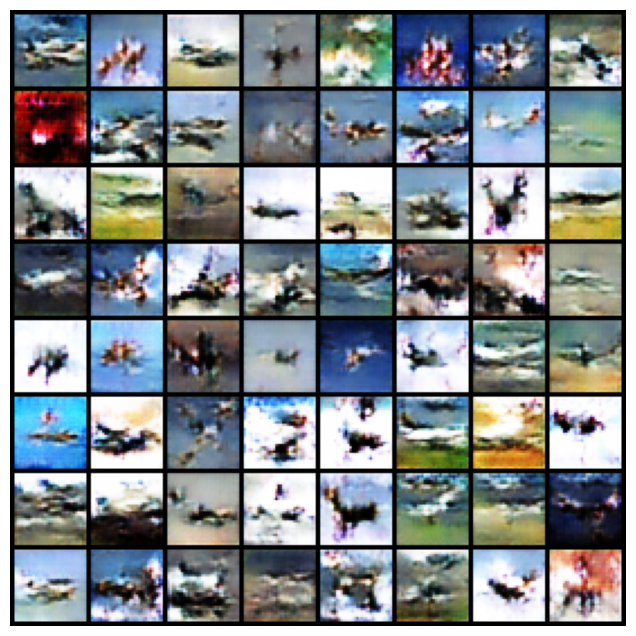

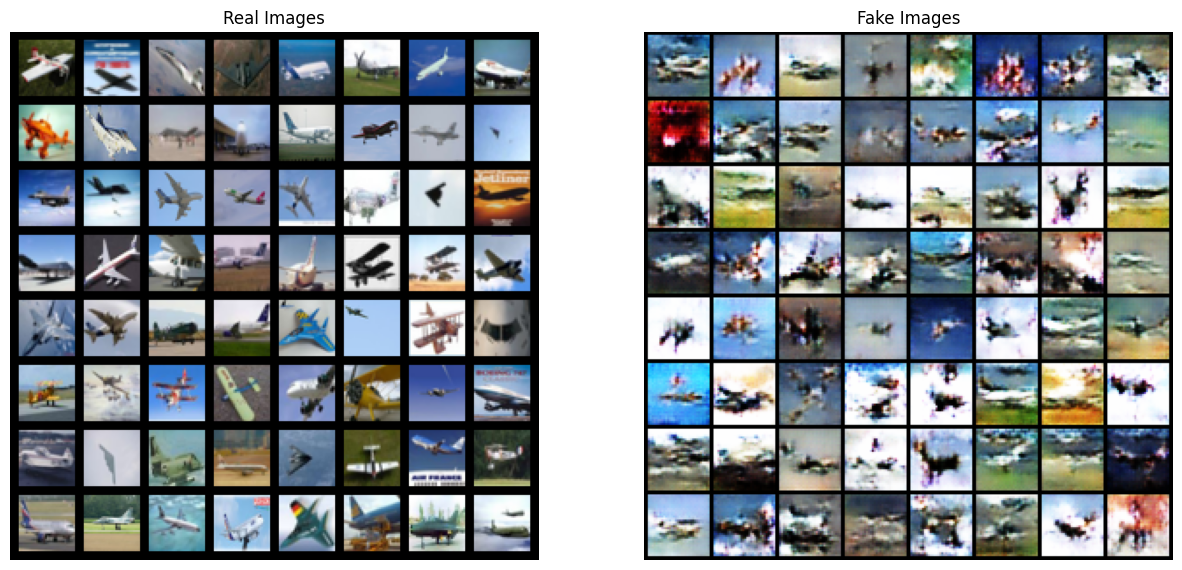

In [ ]:
import torch
import random
import torch.nn as nn
from torchvision.transforms import v2
from torchvision import datasets
from torch.utils.data import DataLoader,Subset
import torch.optim as optim
from tqdm import tqdm #사용할까 고민중..
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import torchvision.utils as vutils
"""
dcgan으로 구현하자. 이게 좀더 선명하다고 하니.
참고:1. gan 논문: https://arxiv.org/pdf/1406.2661
    2. dcgan 논문: https://arxiv.org/pdf/1511.06434
    2. pytorch dcgan 구현: https://docs.pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html
"""
#set seed ->같은 결과를 얻게 하기 위함
manualSeed=18
print("Random Seed:",manualSeed)
random.seed(manualSeed)
torch.manual_seed(manualSeed)
torch.use_deterministic_algorithms(True) # Needed for reproducible results



#데이터 로드-구현간단히 하기 위해 비행기만 사용
transform=v2.Compose([
    v2.ToImage(),                                    # 이미지를 텐서 형태로 변환
    v2.ToDtype(torch.float32, scale=True),            # 0~1 사이 float32로 스케일링
    v2.Normalize((0.5,)*3,(0.5,)*3)         #-1,1 사이의 값으로 또 바꾼다.
])



dataset = datasets.CIFAR10(
        root="./data",
        train=True,
        download=True,
        transform=transform
    )
# CIFAR-10에서 airplane의 label은 0
airplane_indices = [
    i for i, label in enumerate(dataset.targets)
    if label == 0
]
airplane_dataset = Subset(dataset, airplane_indices)

dataloader=DataLoader(airplane_dataset,batch_size=64,shuffle=True,num_workers=0)

# Plot some training images
real_batch = next(iter(dataloader))
plt.figure(figsize=(8,8))
plt.axis("off")
plt.title("Training Images")
plt.imshow(np.transpose(vutils.make_grid(real_batch[0][:64], padding=2, normalize=True).cpu(),(1,2,0)))
plt.show()


def initial_weight(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:          # Conv2d, ConvTranspose2d 둘 다
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.constant_(m.bias, 0)


class DiscriminatorNet(nn.Module):
    def __init__(self):
        super(DiscriminatorNet,self).__init__()
        self.main=nn.Sequential(

            #hiddenlayer1:  inputsize:3*32*32   ->  outputsize:64*16*16
            nn.Conv2d( 3, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(negative_slope=0.2, inplace=True),

            #hiddenlayer2:  inputsize:64*16*16  ->  outputsize:128*8*8
            nn.Conv2d( 64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(negative_slope=0.2, inplace=True),

            #hiddenlayer3:  inputsize:128*8*8 ->  outputsize:256*4*4
            nn.Conv2d( 128, 256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(negative_slope=0.2, inplace=True),

            #hiddenlayer4:  inputsize:256*4*4   ->  outputsize:1*1*1
            nn.Conv2d( 256, 1, kernel_size=4, stride=1, padding=0, bias=False),
            nn.Sigmoid()
        )

    def forward(self,x):
        return self.main(x).view(-1)




class GeneratorNet(nn.Module):
    def __init__(self):
        super(GeneratorNet,self).__init__()

        self.main=nn.Sequential(
            #hidden 1: inputsize:100*1*1->outputsize:256*4*4
            nn.ConvTranspose2d(100,256,kernel_size=4,stride=1,padding=0,bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            #hidden 2:  inputsize:256*4*4 -> outputsize:128*8*8
            nn.ConvTranspose2d(256,128,kernel_size=4,stride=2,padding=1,bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            #hidden 3:  inputsize:128*8*8   ->  outputsize:64*16*16
            nn.ConvTranspose2d(128,64,kernel_size=4,stride=2,padding=1,bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            #hidden 4:  inputsize:64*16*16 ->  outputsize:3*32*32
            nn.ConvTranspose2d(64,3,kernel_size=4,stride=2,padding=1,bias=False),
            nn.Tanh()
        )

    def forward(self,x):
        return self.main(x)



device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
Gnet=GeneratorNet().to(device)
Dnet=DiscriminatorNet().to(device)

Gnet.apply(initial_weight)
Dnet.apply(initial_weight)


criterion=nn.BCELoss()

fixed_noise = torch.randn(64, 100, 1, 1, device=device) #latent vector size

real_label=1
fake_label=0

optimizer_G = optim.Adam(
    Gnet.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
    )
optimizer_D = optim.Adam(
    Dnet.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
    )


#training-
#part1: training discriminator
#part2: trainig generator
num_epochs=30
img_list=[]
G_losses=[]
D_losses=[]
iters=0

print("start training!...")

for epoch in range(num_epochs):
    for i, data in enumerate(dataloader,0):
        ###part1
        #train with real data
        Dnet.zero_grad()
        img=data[0].to(device)
        label=torch.full((img.size(0),),real_label,dtype=torch.float,device=device)

        output=Dnet(img)    #discriminator가 파악한 답일 확률
        D_x = output.mean().item()  #진짜 이미지에 대한 D의 판단
        errD_real=criterion(output,label)   #BCE하기
        errD_real.backward()

        #train with fake data
        noise=torch.randn(img.size(0),100,1,1,device=device)
        fake_img=Gnet(noise)
        label.fill_(fake_label)

        output=Dnet(fake_img.detach())    #generator가 학습되면 안되기 때문에 .detach 사용
        D_G_z1 = output.mean().item()   #D를 업데이트하기 전가짜 이미지에 대한 D의 판단

        errD_fake=criterion(output,label)
        errD_fake.backward()

        errD=errD_real+errD_fake
        optimizer_D.step()

        ###part2
        Gnet.zero_grad()
        label.fill_(real_label)
        output=Dnet(fake_img)
        D_G_z2 = output.mean().item()   #D를 업데이트한 후 가짜 이미지에 대한 판단
        errG=criterion(output,label)
        errG.backward()

        optimizer_G.step()

       # Output training stats
        if i % 50 == 0:
            print('[%d/%d][%d/%d]\tLoss_D: %.4f\tLoss_G: %.4f\tD(x): %.4f\tD(G(z)): %.4f / %.4f'
                  % (epoch, num_epochs, i, len(dataloader),
                     errD.item(), errG.item(), D_x, D_G_z1, D_G_z2))

        # Save Losses for plotting later
        G_losses.append(errG.item())
        D_losses.append(errD.item())

        # Check how the generator is doing by saving G's output on fixed_noise
        if (iters % 500 == 0) or ((epoch == num_epochs-1) and (i == len(dataloader)-1)):
            with torch.no_grad():
                fake = Gnet(fixed_noise).detach().cpu()
            img_list.append(vutils.make_grid(fake, padding=2, normalize=True))

        iters += 1

#결과 출력
#1. loss 그래프
plt.figure(figsize=(10,5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses,label="G")
plt.plot(D_losses,label="D")
plt.xlabel("iterations")
plt.ylabel("Loss")
plt.legend()
plt.savefig("loss.png")
plt.show()

#2. fixed_noise로 만든 이미지가 학습하면서 변하는 과정 -> gif로 저장 (HTML()은 주피터에서만 보임)
fig = plt.figure(figsize=(8,8))
plt.axis("off")
ims = [[plt.imshow(i.permute(1,2,0), animated=True)] for i in img_list]     #(C,H,W) -> (H,W,C)
ani = animation.ArtistAnimation(fig, ims, interval=1000, repeat_delay=1000, blit=True)
ani.save("training.gif", writer=animation.PillowWriter(fps=1))
plt.show()

#3. 진짜 이미지 vs 마지막 가짜 이미지
real_batch = next(iter(dataloader))
plt.figure(figsize=(15,15))
plt.subplot(1,2,1)
plt.axis("off")
plt.title("Real Images")
plt.imshow(vutils.make_grid(real_batch[0][:64], padding=5, normalize=True).permute(1,2,0))

plt.subplot(1,2,2)
plt.axis("off")
plt.title("Fake Images")
plt.imshow(img_list[-1].permute(1,2,0))
plt.savefig("real_vs_fake.png")
plt.show()



